<a href="https://colab.research.google.com/github/miriamamin1213-ux/Ablation_studies/blob/main/HancockXGB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 20.9MB/s]


Dataset shape: (588, 9)

Predictors: ['Age', 'Gender', 'Tobacco Consumption', 'Alcohol Consumption', 'Performance Status', 'T-stage', 'N-stage', 'M-stage']

Target distribution:
HPV_Label
0     58
1    530
Name: count, dtype: int64
Fold 1: train=392, validation=196, threshold=0.865, BA=0.7316
Fold 2: train=392, validation=196, threshold=0.610, BA=0.7733
Fold 3: train=392, validation=196, threshold=0.760, BA=0.8324

3-FOLD RESULTS:
 Fold  N_Train  N_Validation  Scale_Pos_Weight  Accuracy  Balanced_Accuracy  Precision   Recall       F1  Threshold  ROC_AUC   PR_AUC
    1      392           196          0.110482  0.515306           0.731638   1.000000 0.463277 0.633205      0.865 0.770740 0.971060
    2      392           196          0.110482  0.760204           0.773268   0.971014 0.757062 0.850794      0.610 0.812667 0.973425
    3      392           196          0.107345  0.698980           0.832386   1.000000 0.664773 0.798635      0.760 0.841051 0.980853

MEAN ± SD:
                 

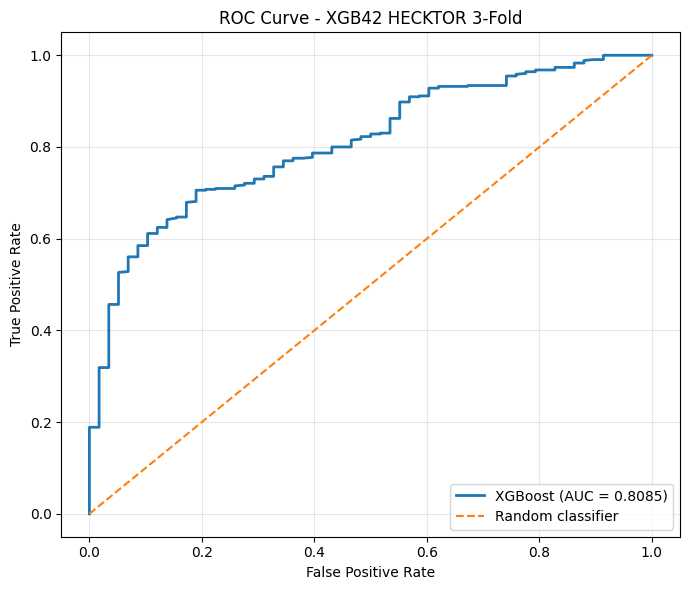

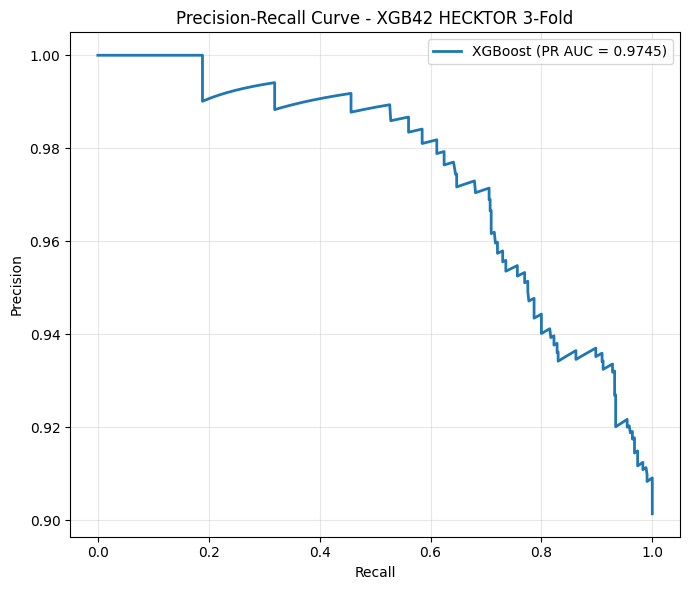

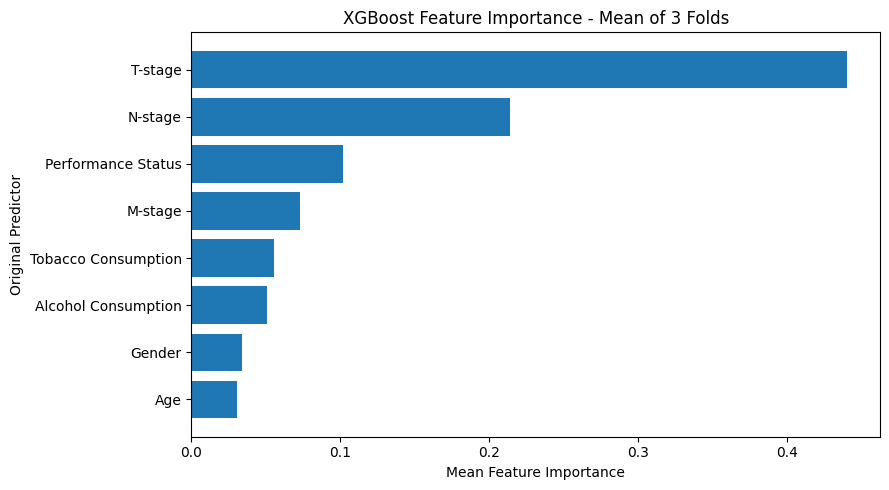

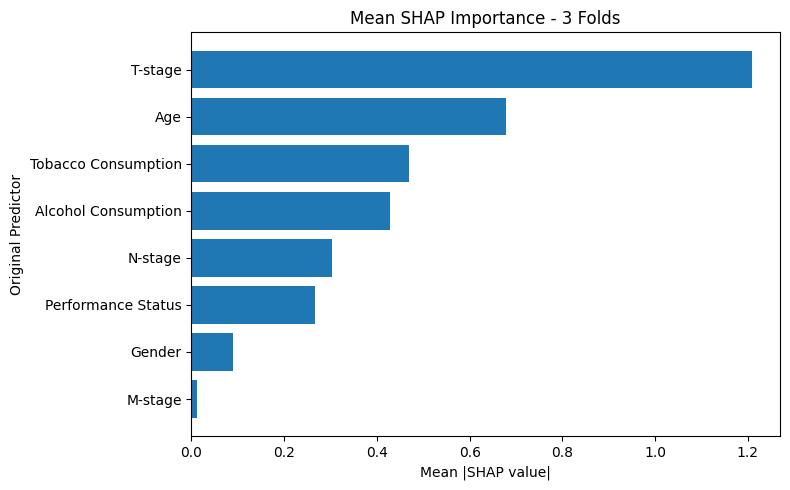

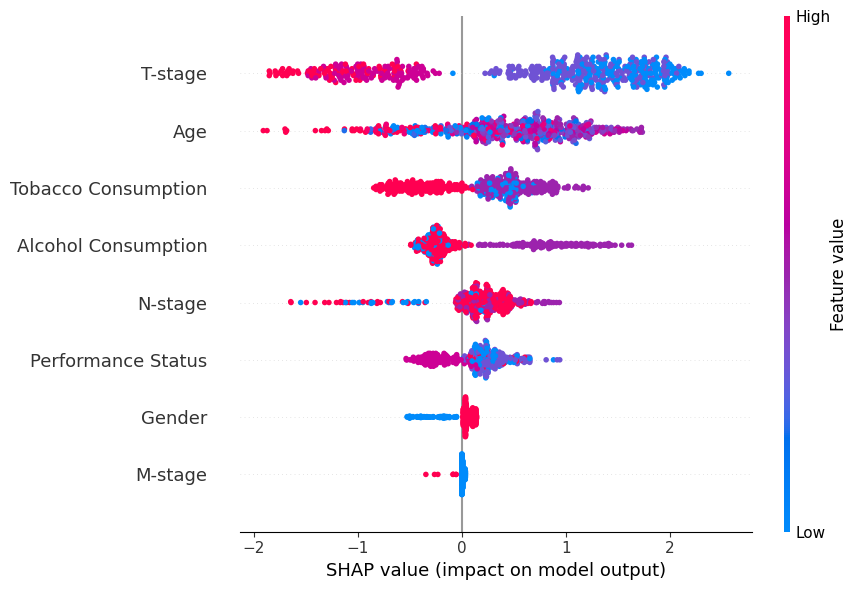

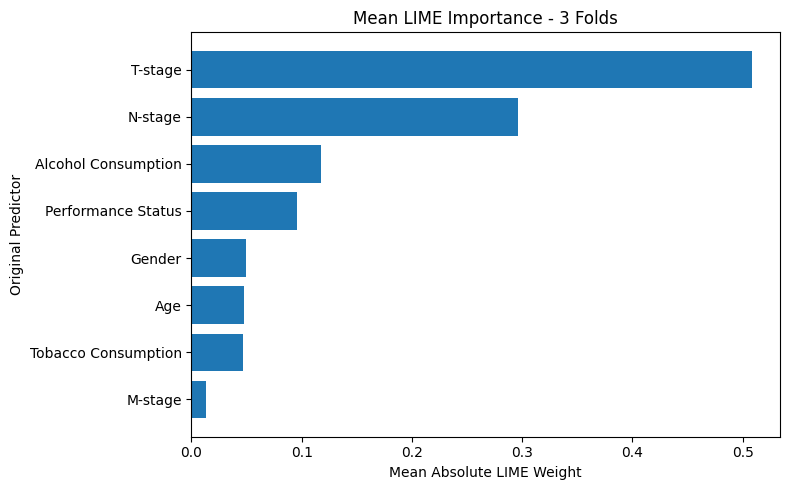


XGBOOST42_HECKTOR 3-FOLD SUMMARY
Model: XGBoost
Original predictors: 8
Estimators: 100
Learning rate: 0.1
Random state: 42
Folds: 3
Split: Stratified 3-fold CV; no test set
Excluded predictors: RFS, Relapse, Treatment
SMOTE: No
Threshold: Validation balanced accuracy within each fold

Mean fold metrics:
                       mean       std
Scale_Pos_Weight   0.109436  0.001811
Accuracy           0.658163  0.127449
Balanced_Accuracy  0.779098  0.050626
Precision          0.990338  0.016735
Recall             0.628371  0.150237
F1                 0.760878  0.113602
Threshold          0.745000  0.128160
ROC_AUC            0.808153  0.035372
PR_AUC             0.975113  0.005110

Pooled out-of-fold metrics:
Accuracy             0.658163
Balanced_Accuracy    0.779668
Precision            0.988131
Recall               0.628302
F1                   0.768166
Threshold            0.745000
ROC_AUC              0.808507
PR_AUC               0.974539
dtype: float64

Saved results folder: /conten

In [1]:
!pip install -q gdown xgboost shap lime
import os,json,random,warnings,joblib,gdown
import numpy as np,pandas as pd,matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from google.colab import drive
from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score,balanced_accuracy_score,
 precision_score,recall_score,f1_score,roc_auc_score,
 average_precision_score,confusion_matrix,classification_report,
 roc_curve,precision_recall_curve)
from xgboost import XGBClassifier
warnings.filterwarnings("ignore",category=FutureWarning)
SEED=42
random.seed(SEED);np.random.seed(SEED)
os.environ["PYTHONHASHSEED"]=str(SEED)
drive.mount("/content/drive")
gdown.download(id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
 output="HPV2025.xlsx",quiet=False)
df=pd.read_excel("HPV2025.xlsx")
df=df.dropna(subset=["HPV Status"]).copy()
columns_to_drop=["PatientID","CenterID","Task 1","Task 2","Task 3"]
df=df.drop(columns=[c for c in columns_to_drop if c in df.columns],
 errors="ignore")
def normalize_label(value):
 if pd.isna(value):return np.nan
 label=str(value).strip().lower()
 if label in {"1","1.0","positive","pos","true","yes"}:return 1
 if label in {"0","0.0","negative","neg","false","no"}:return 0
 return np.nan
df["HPV_Label"]=df["HPV Status"].apply(normalize_label)
df=df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"]=df["HPV_Label"].astype(int)
features=["Age","Gender","Tobacco Consumption","Alcohol Consumption",
 "Performance Status","T-stage","N-stage","M-stage"]
missing_columns=[c for c in features if c not in df.columns]
if missing_columns:
 raise KeyError(f"Missing required predictor columns: {missing_columns}")
model_df=df[features+["HPV_Label"]].copy()
numeric_features=["Age"]
categorical_features=[c for c in features if c not in numeric_features]
missing_strings={"","nan","none","null","na","n/a"}
for col in categorical_features:
 def clean_category(value):
  if pd.isna(value):return np.nan
  value=str(value).strip()
  return np.nan if value.lower() in missing_strings else value
 model_df[col]=model_df[col].apply(clean_category)
model_df["Age"]=pd.to_numeric(model_df["Age"],errors="coerce")
print("Dataset shape:",model_df.shape)
print("\nPredictors:",features)
print("\nTarget distribution:")
print(model_df["HPV_Label"].value_counts().sort_index())
if model_df["HPV_Label"].nunique()!=2:
 raise ValueError("The dataset must contain both HPV classes.")
# STRATIFIED 3-FOLD CROSS-VALIDATION — NO TEST SET
N_SPLITS=3
cv=StratifiedKFold(n_splits=N_SPLITS,shuffle=True,random_state=SEED)
thresholds=np.linspace(0.10,0.90,161)
fold_results=[];oof_true=[];oof_prob=[];oof_pred=[]
shap_values_all=[];shap_data_all=[];shap_plot_data=[];lime_rows=[]
all_importance=[]
def make_preprocessor():
 try:onehot=OneHotEncoder(handle_unknown="ignore",sparse_output=False)
 except TypeError:onehot=OneHotEncoder(handle_unknown="ignore",sparse=False)
 return ColumnTransformer(transformers=[
  ("num",Pipeline([("imputer",SimpleImputer(strategy="median")),
   ("scaler",StandardScaler())]),numeric_features),
  ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
   ("onehot",onehot)]),categorical_features)],
  remainder="drop",verbose_feature_names_out=False)
def calculate_metrics(y_true,probabilities,predictions,threshold):
 both_classes=len(np.unique(y_true))==2
 return {"Accuracy":accuracy_score(y_true,predictions),
  "Balanced_Accuracy":balanced_accuracy_score(y_true,predictions),
  "Precision":precision_score(y_true,predictions,zero_division=0),
  "Recall":recall_score(y_true,predictions,zero_division=0),
  "F1":f1_score(y_true,predictions,zero_division=0),
  "Threshold":float(threshold),
  "ROC_AUC":roc_auc_score(y_true,probabilities) if both_classes else np.nan,
  "PR_AUC":average_precision_score(y_true,probabilities)
  if both_classes else np.nan}
def original_feature(name):
 for feature in features:
  if name==feature or name.startswith(feature+"_"):return feature
 return name
for fold,(train_idx,val_idx) in enumerate(cv.split(model_df[features],
 model_df["HPV_Label"]),1):
 train=model_df.iloc[train_idx].copy()
 val=model_df.iloc[val_idx].copy()
 preprocessor=make_preprocessor()
 X_train=preprocessor.fit_transform(train[features])
 X_val=preprocessor.transform(val[features])
 y_train=train["HPV_Label"].to_numpy()
 y_val=val["HPV_Label"].to_numpy()
 try:encoded_names=preprocessor.get_feature_names_out().tolist()
 except (AttributeError,TypeError):
  encoded_names=[f"encoded_feature_{i}" for i in range(X_train.shape[1])]
 counts=np.bincount(y_train,minlength=2)
 if np.any(counts==0):raise ValueError("Both classes must be in each training fold.")
 scale_pos_weight=float(counts[0]/counts[1])
 model=XGBClassifier(n_estimators=100,learning_rate=0.1,
  scale_pos_weight=scale_pos_weight,random_state=SEED,eval_metric="logloss")
 model.fit(X_train,y_train)
 val_prob=model.predict_proba(X_val)[:,1]
 threshold_scores=[balanced_accuracy_score(y_val,(val_prob>=t).astype(int))
  for t in thresholds]
 best_score=max(threshold_scores)
 best_threshold=float(min((t for t,s in zip(thresholds,threshold_scores)
  if s==best_score),key=lambda t:abs(t-0.5)))
 val_pred=(val_prob>=best_threshold).astype(int)
 metrics=calculate_metrics(y_val,val_prob,val_pred,best_threshold)
 fold_results.append({"Fold":fold,"N_Train":len(train),"N_Validation":len(val),
  "Scale_Pos_Weight":scale_pos_weight,**metrics})
 oof_true.extend(y_val.tolist());oof_prob.extend(val_prob.tolist())
 oof_pred.extend(val_pred.tolist())
 # SHAP values, grouped back to the eight original predictors
 explainer=shap.TreeExplainer(model)
 sv=explainer.shap_values(X_val)
 if isinstance(sv,list):sv=sv[-1]
 sv=np.asarray(sv)
 if sv.ndim==3:sv=sv[:,:,1]
 grouped=np.column_stack([sv[:,[i for i,n in enumerate(encoded_names)
  if original_feature(n)==feature]].sum(axis=1)
  if any(original_feature(n)==feature for n in encoded_names)
  else np.zeros(len(val)) for feature in features])
 shap_values_all.append(grouped)
 shap_data_all.append(val[features].reset_index(drop=True))
 plot_values={}
 for feature in features:
  if feature=="Age":plot_values[feature]=pd.to_numeric(val[feature],errors="coerce")
  else:
   categories=pd.Categorical(model_df[feature]).categories
   plot_values[feature]=pd.Categorical(val[feature],categories=categories).codes
 shap_plot_data.append(pd.DataFrame(plot_values))
 # LIME local explanations, averaged over validation patients
 lime_explainer=LimeTabularExplainer(np.asarray(X_train),
  feature_names=encoded_names,class_names=["HPV Negative","HPV Positive"],
  mode="classification",discretize_continuous=True,random_state=SEED)
 for row in np.asarray(X_val):
  explanation=lime_explainer.explain_instance(row,model.predict_proba,
   num_features=len(encoded_names))
  weights=dict(explanation.as_list(label=1))
  row_importance={feature:0.0 for feature in features}
  for term,weight in weights.items():
   for feature in features:
    if term==feature or term.startswith(feature+"_") or term.startswith(feature+" "):
     row_importance[feature]+=abs(float(weight));break
  lime_rows.append(row_importance)
 # Native XGBoost importance, grouped to original predictors
 importance=dict(zip(encoded_names,model.feature_importances_))
 all_importance.append({feature:sum(value for name,value in importance.items()
  if original_feature(name)==feature) for feature in features})
 print(f"Fold {fold}: train={len(train)}, validation={len(val)}, "
  f"threshold={best_threshold:.3f}, BA={metrics['Balanced_Accuracy']:.4f}")
# POOLED OUT-OF-FOLD METRICS
oof_true=np.asarray(oof_true);oof_prob=np.asarray(oof_prob)
oof_pred=np.asarray(oof_pred)
fold_df=pd.DataFrame(fold_results)
summary_df=fold_df.drop(columns=["Fold","N_Train","N_Validation"]).agg(
 ["mean","std"]).T
oof_metrics=calculate_metrics(oof_true,oof_prob,oof_pred,
 float(fold_df["Threshold"].mean()))
print("\n3-FOLD RESULTS:")
print(fold_df.to_string(index=False))
print("\nMEAN ± SD:")
print(summary_df)
print("\nPOOLED OUT-OF-FOLD METRICS:")
print(pd.Series(oof_metrics))
cm=confusion_matrix(oof_true,oof_pred,labels=[0,1])
print("\nOut-of-fold confusion matrix:\n",cm)
print("\nOut-of-fold classification report:\n",
 classification_report(oof_true,oof_pred,labels=[0,1],
 target_names=["HPV Negative","HPV Positive"],zero_division=0))
# SAVE RESULTS
OUT_DIR="/content/drive/MyDrive/XGB_results_HECKTOR_3fold"
os.makedirs(OUT_DIR,exist_ok=True)
fold_df.to_csv(os.path.join(OUT_DIR,"fold_metrics.csv"),index=False)
summary_df.to_csv(os.path.join(OUT_DIR,"metrics_mean_sd.csv"))
oof_df=pd.DataFrame({"y_true":oof_true,"probability_positive":oof_prob,
 "prediction":oof_pred})
oof_df.to_csv(os.path.join(OUT_DIR,"oof_predictions.csv"),index=False)
settings={"model":"XGBClassifier","dataset":"HPV2025.xlsx","seed":SEED,
 "features":features,"target_column":"HPV Status","folds":N_SPLITS,
 "threshold_selection":"Maximum validation balanced accuracy per fold",
 "smote":False,"model_parameters":{"n_estimators":100,"learning_rate":0.1,
 "eval_metric":"logloss"},"validation_design":"Stratified 3-fold CV; no test set"}
with open(os.path.join(OUT_DIR,"settings.json"),"w",encoding="utf-8") as f:
 json.dump(settings,f,indent=2)
print("\nSaved results to:",OUT_DIR)
# ROC / PR CURVES — POOLED OUT-OF-FOLD PREDICTIONS
fpr,tpr,_=roc_curve(oof_true,oof_prob)
auc_curve=roc_auc_score(oof_true,oof_prob)
plt.figure(figsize=(7,6))
plt.plot(fpr,tpr,linewidth=2,label=f"XGBoost (AUC = {auc_curve:.4f})")
plt.plot([0,1],[0,1],linestyle="--",linewidth=1.5,label="Random classifier")
plt.xlabel("False Positive Rate");plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGB42 HECKTOR 3-Fold")
plt.legend(loc="lower right");plt.grid(alpha=0.3);plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"roc_curve_3fold.png"),dpi=300,
 bbox_inches="tight")
plt.show()
precision_values,recall_values,_=precision_recall_curve(oof_true,oof_prob)
pr_auc_curve=average_precision_score(oof_true,oof_prob)
plt.figure(figsize=(7,6))
plt.plot(recall_values,precision_values,linewidth=2,
 label=f"XGBoost (PR AUC = {pr_auc_curve:.4f})")
plt.xlabel("Recall");plt.ylabel("Precision")
plt.title("Precision-Recall Curve - XGB42 HECKTOR 3-Fold")
plt.legend(loc="best");plt.grid(alpha=0.3);plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"precision_recall_curve_3fold.png"),
 dpi=300,bbox_inches="tight")
plt.show()
# XGBOOST FEATURE IMPORTANCE — MEAN ACROSS THREE FOLDS
importance_df=pd.DataFrame(all_importance).mean().rename_axis("feature").reset_index(
 name="importance").sort_values("importance",ascending=False)
importance_df.to_csv(os.path.join(OUT_DIR,"feature_importance_mean_3fold.csv"),
 index=False)
plt.figure(figsize=(9,5))
plt.barh(importance_df.sort_values("importance")["feature"],
 importance_df.sort_values("importance")["importance"])
plt.xlabel("Mean Feature Importance");plt.ylabel("Original Predictor")
plt.title("XGBoost Feature Importance - Mean of 3 Folds")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"feature_importance_mean_3fold.png"),
 dpi=300,bbox_inches="tight")
plt.show()
# MEAN ABSOLUTE SHAP IMPORTANCE ACROSS THREE FOLDS
shap_matrix=np.vstack(shap_values_all)
mean_shap=np.mean(np.abs(shap_matrix),axis=0)
shap_mean_df=pd.DataFrame({"feature":features,"mean_abs_shap":mean_shap})
shap_mean_df=shap_mean_df.sort_values("mean_abs_shap",ascending=False)
shap_mean_df.to_csv(os.path.join(OUT_DIR,"shap_mean_importance_3fold.csv"),
 index=False)
plt.figure(figsize=(8,5))
plt.barh(shap_mean_df.sort_values("mean_abs_shap")["feature"],
 shap_mean_df.sort_values("mean_abs_shap")["mean_abs_shap"])
plt.xlabel("Mean |SHAP value|");plt.ylabel("Original Predictor")
plt.title("Mean SHAP Importance - 3 Folds")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"shap_mean_importance_3fold.png"),dpi=300,
 bbox_inches="tight")
plt.show()
# SHAP BEESWARM — POOLED OUT-OF-FOLD VALUES, EIGHT ORIGINAL PREDICTORS
shap.summary_plot(shap_matrix,pd.concat(shap_plot_data,ignore_index=True)
 [features],feature_names=features,show=False,max_display=len(features))
plt.gcf().set_size_inches(9,6);plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"shap_beeswarm_3fold.png"),dpi=300,
 bbox_inches="tight")
plt.show()
# MEAN ABSOLUTE LIME IMPORTANCE ACROSS THREE FOLDS
lime_df=pd.DataFrame(lime_rows)
lime_mean=lime_df[features].mean().sort_values(ascending=False)
lime_mean_df=lime_mean.rename("mean_abs_lime").reset_index(
 name="mean_abs_lime").rename(columns={"index":"feature"})
lime_mean_df.to_csv(os.path.join(OUT_DIR,"lime_mean_importance_3fold.csv"),
 index=False)
plt.figure(figsize=(8,5))
plt.barh(lime_mean_df.sort_values("mean_abs_lime")["feature"],
 lime_mean_df.sort_values("mean_abs_lime")["mean_abs_lime"])
plt.xlabel("Mean Absolute LIME Weight");plt.ylabel("Original Predictor")
plt.title("Mean LIME Importance - 3 Folds")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"lime_mean_importance_3fold.png"),dpi=300,
 bbox_inches="tight")
plt.show()
print("\n====================================")
print("XGBOOST42_HECKTOR 3-FOLD SUMMARY")
print("====================================")
print("Model: XGBoost")
print("Original predictors:",len(features))
print("Estimators: 100");print("Learning rate: 0.1")
print("Random state:",SEED);print("Folds:",N_SPLITS)
print("Split: Stratified 3-fold CV; no test set")
print("Excluded predictors: RFS, Relapse, Treatment")
print("SMOTE: No")
print("Threshold: Validation balanced accuracy within each fold")
print("\nMean fold metrics:")
print(summary_df)
print("\nPooled out-of-fold metrics:")
print(pd.Series(oof_metrics))
print("\nSaved results folder:",OUT_DIR)
print("Analysis complete.")
